# Understanding SK Learn Essentials

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, mean_absolute_error, r2_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
DATA = Path("../data")
OUTPUT = Path("../output")

OUTPUT.mkdir(exist_ok=True)

In [4]:
subscriptions = pd.read_csv(DATA / "subscriptions.csv")
closed = subscriptions[subscriptions["renewal_status"] != "Open"].copy()
closed["churned"] = (closed["renewal_status"] == "Churned").astype(int)

print("Closed Renewals : ", len(closed), " | Churned: ", closed["churned"].sum(
), " | Churn Rate : ", round(closed["churned"].mean(), 3))

Closed Renewals :  795  | Churned:  180  | Churn Rate :  0.226


In [5]:
FEATURES = ["avg_seat_utilization", "utilization_trend", "avg_feature_adoption",
            "support_cases_12m", "sev1_cases_12m", "nps_score", "term_months", "auto_renew"]

X = closed[FEATURES].astype(float)
y = closed["churned"]

print("X: ", X.shape, " | y: ", y.shape)

X:  (795, 8)  | y:  (795,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train :", X_train.shape, " Test: ", X_test.shape, " | Churn Rate Train ",
      round(y_train.mean(), 3), " Test : ", round(y_test.mean(), 3))

Train : (636, 8)  Test:  (159, 8)  | Churn Rate Train  0.226  Test :  0.226


In [ ]:
# dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
# dummy_predictions = dummy.predict(X_test)

# print("Accuracy :", round(accuracy_score(y_test, dummy_predictions), 3),
#       " | Churners Caught : ", round(recall_score(y_test, dummy_predictions), 3))

Accuracy : 0.774  | Churners Caught :  0.0


In [9]:
tree = DecisionTreeClassifier(
    max_depth=3, random_state=42).fit(X_train, y_train)
predictions = tree.predict(X_test)

print("Accuracy : ", round(accuracy_score(y_test, predictions), 3),
      " | Churners Caught : ", round(recall_score(y_test, predictions), 3))

print("Confusion Matrix :", confusion_matrix(y_test, predictions))

Accuracy :  0.805  | Churners Caught :  0.417
Confusion Matrix : [[113  10]
 [ 21  15]]


In [11]:
tree_b = DecisionTreeClassifier(
    max_depth=3, class_weight="balanced", random_state=42).fit(X_train, y_train)
predictions = tree_b.predict(X_test)

print("Accuracy : ", round(accuracy_score(y_test, predictions), 3),
      " | Churners Caught : ", round(recall_score(y_test, predictions), 3))

print("Confusion Matrix :", confusion_matrix(y_test, predictions))

Accuracy :  0.642  | Churners Caught :  0.889
Confusion Matrix : [[70 53]
 [ 4 32]]


In [12]:
importance = pd.Series(tree_b.feature_importances_,
                       index=FEATURES).sort_values(ascending=False)
print("Feature Importance by %", importance.round(3))

Feature Importance by % utilization_trend       0.672
avg_seat_utilization    0.254
support_cases_12m       0.041
nps_score               0.034
avg_feature_adoption    0.000
sev1_cases_12m          0.000
term_months             0.000
auto_renew              0.000
dtype: float64


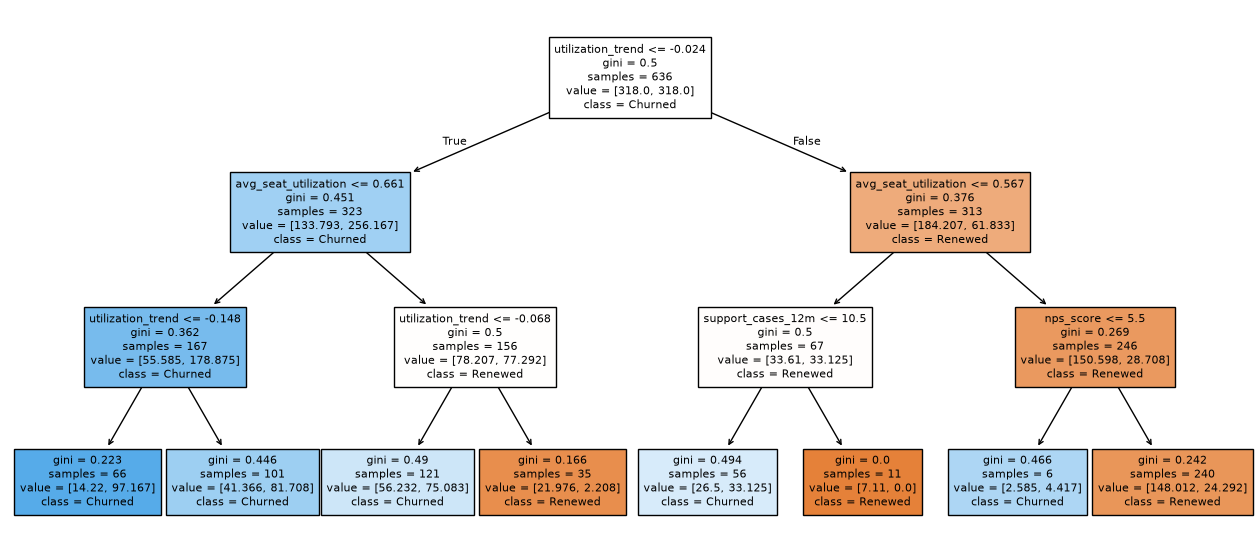

In [13]:
figure, axes = plt.subplots(figsize=(16, 7))
plot_tree(tree_b, feature_names=FEATURES,
          class_names=["Renewed", "Churned"], filled=True, ax=axes, fontsize=8)

figure.savefig(OUTPUT / "d2_1_tree.png", dpi=110, bbox_inches="tight")

plt.show()

In [17]:
X_tmp, X_test2, y_tmp, y_test2 = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

rows = []
for depth in range(1, 9):
    m = DecisionTreeClassifier(max_depth=depth,
                               class_weight="balanced",
                               random_state=42).fit(X_tr, y_tr)

    rows.append({
        "max_depth": depth,
        "train_bal_acc": balanced_accuracy_score(y_tr, m.predict(X_tr)),
        "val_bal_acc": balanced_accuracy_score(y_val, m.predict(X_val))
    })

res = pd.DataFrame(rows).round(3)
print(res.to_string(index=False))

best = int(res.loc[res["val_bal_acc"].idxmax(), "max_depth"])

print("Best : ", best)

final = DecisionTreeClassifier(
    max_depth=best, class_weight="balanced", random_state=42).fit(X_tmp, y_tmp)

p = final.predict(X_test2)

print(
    f"Chosen Max Depth : {best} -> Test Balanced Accuracy : {balanced_accuracy_score(y_test2, p):3f},")
print(
    f"Accuracy : {accuracy_score(y_test2, p):3f}, Churners Caught : {recall_score(y_test2, p):3f}")

 max_depth  train_bal_acc  val_bal_acc
         1          0.699        0.673
         2          0.761        0.550
         3          0.785        0.602
         4          0.810        0.592
         5          0.850        0.574
         6          0.900        0.524
         7          0.918        0.517
         8          0.948        0.536
Best :  1
Chosen Max Depth : 1 -> Test Balanced Accuracy : 0.683943,
Accuracy : 0.647799, Churners Caught : 0.750000
